# Module 3 공정 레시피 추천

- 저장된 Ni·Co SVR 모델을 재학습 없이 사용함
- 원료 조성과 원료투입량 고정 후 황산량·온도·시간 탐색함
- 목표는 Ni 95%, Co 90%이며 실제 달성 보장이 아닌 예측 기준임
- 운전 부담은 세 변수의 범위 정규화 후 동일 가중 평균이며 실제 비용이 아님
- Differential Evolution·유전 알고리즘 각각 3개 seed와 9×9×9 격자 탐색 비교함
- GA는 개체 36개·60세대, 토너먼트 선택·산술 교차·돌연변이·상위 2개체 보존 적용함
- 황산 1 L, 온도 0.1°C, 시간 0.1 h는 시연용 반올림 단위이며 설비 해상도는 아님
- 반올림 후 다시 예측하여 목표 충족 여부 판정함
- 미발견은 탐색 예산 내 결과이며 달성 불가능을 증명하지 않음

프로젝트 루트에서 결과 재생성 가능함
```bash
python -m module3_optimization.pipeline --input module3_optimization/examples/blend_7_3.json
python -m module3_optimization.scripts.test_batch_examples
```
아래는 reports의 A·C·7:3 예제와 Test 배치 실행 결과를 읽어 재검증함


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['font.family'] = ['Noto Sans CJK JP', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
from IPython.display import display, Image
from module2_prediction.artifacts import load_bundle
from module3_optimization.optimization import predict_candidates
from module3_optimization.validation import validate_controls, outcome
from module3_optimization.config import TARGETS, CONTROL_COLUMNS, BOUNDS
root = Path('..')
reports = root / 'module3_optimization/reports'
bundles = {t: load_bundle(root / 'module2_prediction/reports/final' / f'{t}.joblib') for t in TARGETS}

def plot_slice(feed, result, x_idx, y_idx, fixed_idx):
    """두 변수를 바꾸고 나머지 하나는 추천값에 고정한 예측 회수율 단면을 그림"""
    x_name, y_name, fixed_name = (CONTROL_COLUMNS[i] for i in (x_idx, y_idx, fixed_idx))
    x = np.linspace(*BOUNDS[x_idx], 31)
    y = np.linspace(*BOUNDS[y_idx], 31)
    xx, yy = np.meshgrid(x, y)
    controls = np.zeros((xx.size, 3))
    controls[:, x_idx], controls[:, y_idx] = xx.ravel(), yy.ravel()
    controls[:, fixed_idx] = result['controls'][fixed_name]
    values = predict_candidates(bundles, feed, controls)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    for i, (ax, target) in enumerate(zip(axes, TARGETS)):
        z = values[:, i].reshape(xx.shape)
        im = ax.pcolormesh(xx, yy, z, shading='auto', vmin=0, vmax=100, cmap='viridis')
        level = result['targets'][target]
        if z.min() < level < z.max():
            ax.contour(xx, yy, z, levels=[level], colors='white')
        ax.scatter(result['controls'][x_name], result['controls'][y_name], marker='*', color='red', s=90)
        ax.set(xlabel=x_name, ylabel=y_name, title=f'{target.split("_")[0]} predicted recovery (%)')
    fig.colorbar(im, ax=axes, label='Predicted recovery (%)')
    fig.suptitle(f'{fixed_name} fixed at {result["controls"][fixed_name]:.2f}')
    plt.show()
    plt.close(fig)


## 1. 입력과 추천 결과

- A·C는 가상 분석값으로 만든 예제이며 실측 배치가 아님
- 7:3은 두 조성을 질량 기준으로 혼합한 예제임
- 동일 원료의 현재 조건과 추천 조건을 비교함


In [2]:
rows = []
results = {}
for name in ['a_example', 'c_example', 'blend_7_3']:
    result = json.loads((reports / name / 'recommendation.json').read_text())
    results[name] = result
    controls = [result['controls'][c] for c in CONTROL_COLUMNS]
    validate_controls(controls)
    predictions = predict_candidates(bundles, result['feed'], [controls])[0]
    np.testing.assert_allclose(predictions, [result['predictions'][t] for t in TARGETS], atol=1e-10)
    valid, feasible, margins = outcome(dict(zip(TARGETS, predictions)), result['targets'])
    assert valid and feasible == (result['status'] == 'predicted_feasible')
    row = dict(scenario=name, status=result['status'], **result['controls'], **result['predictions'], burden=result['burden'])
    current = result.get('current')
    if current is None:
        row['current_comparison'] = '현재 조건 입력 없음'
    elif current['predictions'] is None:
        row['current_comparison'] = current['comparison_excluded_reason']
    else:
        row.update({f'current_{t}': v for t, v in current['predictions'].items()})
        row.update({f'change_{t}': v for t, v in result['predicted_change_pct_point'].items()})
    rows.append(row)
pd.DataFrame(rows)


,scenario,status,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct,burden,current_Ni_회수율_pct,current_Co_회수율_pct,change_Ni_회수율_pct,change_Co_회수율_pct
0,a_example,predicted_feasible,1178.0,94.4,5.3,95.364488,90.001519,0.770216,88.448374,82.898028,6.916115,7.103492
1,c_example,target_not_found,1500.0,95.0,7.6,88.113341,79.224393,0.980952,79.620486,70.038632,8.492855,9.185761
2,blend_7_3,target_not_found,1500.0,95.0,7.1,95.797849,88.996762,0.957143,85.826607,79.171025,9.971242,9.825737


## 2. Test 배치 실측 대비 추천 비교

- `python -m module3_optimization.scripts.test_batch_examples`로 생성한, 결측 없는 Test 배치 전체의 추천 결과를 비교함
- Test는 추천 요청의 입력(실측 조성·운전조건·회수율)으로만 사용하며, Module 2 모델·Module 3 설정(가중치·여유폭·알고리즘) 재선택에는 쓰지 않음(위 §1의 가상 예제와 달리 실제 배치임)
- `current_*`는 실측 운전조건에서의 모델 예측, `predicted_*`는 추천 조건에서의 모델 예측 — 둘의 차이는 모델 예측상 개선폭이며 실제 재실험 결과가 아님


In [3]:
test_batch_dir = reports / 'test_batches'
test_summary = pd.read_csv(test_batch_dir / 'summary.csv')
test_metadata = json.loads((test_batch_dir / 'metadata.json').read_text())
print(f"선정 배치: {test_metadata['selected_batch_count']} / 전체 Test 배치: {test_metadata['total_test_batches']}")
print('등급별 선정 배치 수:', {g: len(ids) for g, ids in test_metadata['selected_batches'].items()})
print('추천 상태 분포:', test_summary['status'].value_counts().to_dict())
display(test_summary.groupby('grade')['status'].value_counts().unstack(fill_value=0))
test_summary


선정 배치: 34 / 전체 Test 배치: 63
등급별 선정 배치 수: {'A': 13, 'B': 13, 'C': 8}
추천 상태 분포: {'target_not_found': 19, 'predicted_feasible': 15}


status,predicted_feasible,target_not_found
grade,,
A,11,2
B,4,9
C,0,8


,grade,batch_id,status,actual_Ni_회수율_pct,actual_Co_회수율_pct,actual_control_황산투입량_L,actual_control_침출온도_C,actual_control_침출시간_hr,recommended_황산투입량_L,recommended_침출온도_C,recommended_침출시간_hr,predicted_Ni_회수율_pct,predicted_Co_회수율_pct,model_predicted_at_actual_control_Ni_회수율_pct,model_predicted_at_actual_control_Co_회수율_pct
0,A,BP-2025-0009,predicted_feasible,89.11,82.10,712.0,81.6,6.10,1377.0,91.1,6.2,95.001185,90.001932,89.233120,85.470261
1,A,BP-2025-0051,predicted_feasible,96.91,88.14,1130.0,83.9,7.41,1296.0,95.0,5.5,96.228010,90.002153,95.490353,88.880796
2,B,BP-2025-0066,target_not_found,83.99,74.56,1294.0,43.2,4.10,1500.0,95.0,7.3,94.552113,87.836468,82.657517,74.307751
3,A,BP-2025-0071,predicted_feasible,95.98,89.90,922.0,91.7,4.71,910.0,83.6,5.1,95.618691,90.000612,96.016229,90.598405
4,C,BP-2025-0073,target_not_found,81.48,70.78,825.0,66.1,4.38,1500.0,95.0,7.7,88.567760,79.298157,79.139305,68.671905
5,C,BP-2025-0080,target_not_found,76.41,65.00,640.0,47.0,4.51,1500.0,95.0,7.2,91.029620,82.413557,77.095621,65.801490
6,C,BP-2025-0083,target_not_found,79.02,70.29,1415.0,52.9,4.55,1500.0,95.0,7.7,87.927605,79.273270,80.011039,69.906894
7,B,BP-2025-0094,target_not_found,78.75,71.41,947.0,89.1,1.04,1500.0,95.0,7.5,92.659656,85.018307,80.706779,73.837121
8,B,BP-2025-0102,predicted_feasible,89.00,78.24,610.0,76.3,7.41,1447.0,95.0,6.7,96.355316,90.000163,89.397849,83.140664
9,A,BP-2025-0113,predicted_feasible,88.92,81.15,1186.0,49.1,7.69,1170.0,93.9,5.0,96.429403,90.001143,91.804897,84.474581


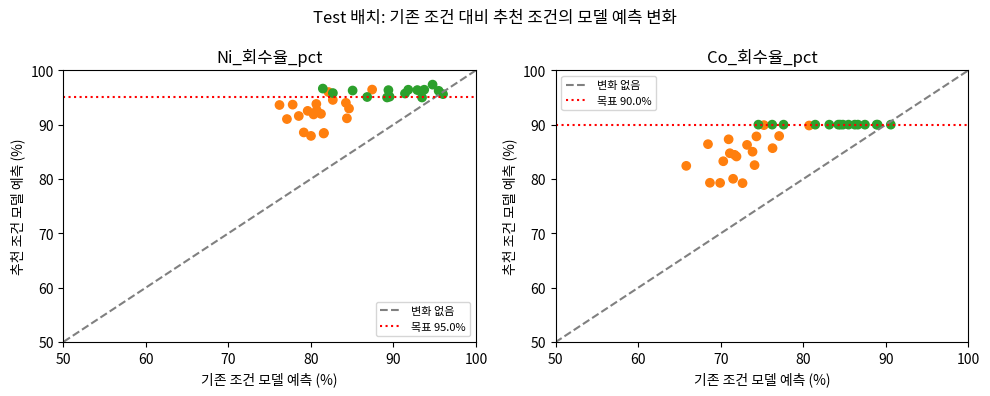

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, TARGETS):
    before = test_summary[f'model_predicted_at_actual_control_{t}']
    after = test_summary[f'predicted_{t}']
    ax.scatter(before, after, c=test_summary['status'].map({'predicted_feasible': 'tab:green', 'target_not_found': 'tab:orange'}))
    ax.plot([0, 100], [0, 100], '--', color='gray', label='변화 없음')
    ax.axhline(TARGETS[t], color='red', linestyle=':', label=f'목표 {TARGETS[t]}%')
    ax.set(xlim=(50, 100), ylim=(50, 100), xlabel='기존 조건 모델 예측 (%)', ylabel='추천 조건 모델 예측 (%)', title=t)
    ax.legend(fontsize=8)
fig.suptitle('Test 배치: 기존 조건 대비 추천 조건의 모델 예측 변화')
fig.tight_layout()
plt.show()
plt.close(fig)


## 3. Test 배치 상세 분석 (보고서 표 5·그림 11 기준)

- **배치 선정 기준(회수율 결과와 무관, 사전에 정한 규칙)**: §2의 추천 상태(`predicted_feasible`/`target_not_found`) 각각에서 배치ID 사전순 첫 번째를 선정함 — 예측상 목표를 충족한 사례와 충족하지 못한 사례를 하나씩 대표로 보여주기 위함
- 아래 알고리즘 비교는 격자·DE·GA 각 출처의 **최종 후보가 목표를 충족했는지와 운전 부담(정규화 가중합)** 중심으로 설명함 — 탐색 과정의 수렴 여부 자체는 §4의 가상 예제에서 다룸
- 회수율 변화는 **모델 예측 결과**이며 실제 재실험으로 확인한 개선이 아님


In [5]:
detail_batch_ids = {}
for status in ['predicted_feasible', 'target_not_found']:
    candidates_for_status = test_summary[test_summary.status == status].sort_values('batch_id')
    if not candidates_for_status.empty:
        detail_batch_ids[status] = candidates_for_status.iloc[0]['batch_id']
print('선정 배치:', detail_batch_ids)

detail_results = {}
for status, batch_id in detail_batch_ids.items():
    detail_results[batch_id] = json.loads((test_batch_dir / batch_id / 'recommendation.json').read_text())


선정 배치: {'predicted_feasible': 'BP-2025-0009', 'target_not_found': 'BP-2025-0066'}


In [6]:
for batch_id, result in detail_results.items():
    print(f'=== {batch_id} (상태: {result["status"]}) ===')
    comparison = pd.read_csv(test_batch_dir / batch_id / 'search_comparison.csv')
    display(comparison[['source', 'feasible', 'burden', 'deficit']])
    feasible_rows = comparison[comparison.feasible]
    if feasible_rows.empty:
        print(f'  격자·DE 3개 seed·GA 3개 seed(7개 출처) 전부 목표 미충족 — 최소 deficit={comparison["deficit"].min():.3f}%p')
    else:
        best = feasible_rows.sort_values('burden').iloc[0]
        print(f'  목표 충족 출처 {len(feasible_rows)}개, 운전 부담 최솟값={best["burden"]:.3f}({best["source"]})')
    print(f'  최종 선택 출처: {result["selected_source"]}, 운전 부담={result["burden"]:.3f}, 목표 대비 여유(%p)={result["margins_pct_point"]}')
    print()


=== BP-2025-0009 (상태: predicted_feasible) ===


,source,feasible,burden,deficit
0,de_42,True,0.853377,0.0
1,de_7,True,0.853377,0.0
2,de_83,True,0.853377,0.0
3,ga_42,True,0.853680,0.0
4,ga_7,True,0.853983,0.0
5,ga_83,True,0.854372,0.0
6,grid,True,0.872468,0.0


  목표 충족 출처 7개, 운전 부담 최솟값=0.853(de_42)
  최종 선택 출처: de_42, 운전 부담=0.853, 목표 대비 여유(%p)={'Ni_회수율_pct': 0.0011849787675828338, 'Co_회수율_pct': 0.001932417209502546}

=== BP-2025-0066 (상태: target_not_found) ===


,source,feasible,burden,deficit
0,de_42,False,0.966667,2.611419
1,de_7,False,0.966667,2.611419
2,de_83,False,0.966667,2.611419
3,ga_42,False,0.966667,2.611419
4,ga_7,False,0.966667,2.611419
5,ga_83,False,0.966667,2.611419
6,grid,False,0.957143,2.631677


  격자·DE 3개 seed·GA 3개 seed(7개 출처) 전부 목표 미충족 — 최소 deficit=2.611%p
  최종 선택 출처: de_42, 운전 부담=0.967, 목표 대비 여유(%p)={'Ni_회수율_pct': -0.447887046944345, 'Co_회수율_pct': -2.163532102395891}



### 예측 회수율 변화 (그림 11 기준)

- 추천 조건을 기준으로 두 변수를 바꾸고 나머지 하나는 고정한 단면임 — **모델 예측값**이며 실제 재현 결과가 아님
- 흰색 선은 목표 회수율, 별/엑스 표시는 추천 후보(목표 미충족 시 탐색 예산 내 가장 가까운 후보)


BP-2025-0009 (상태: predicted_feasible) — 예측 회수율 변화


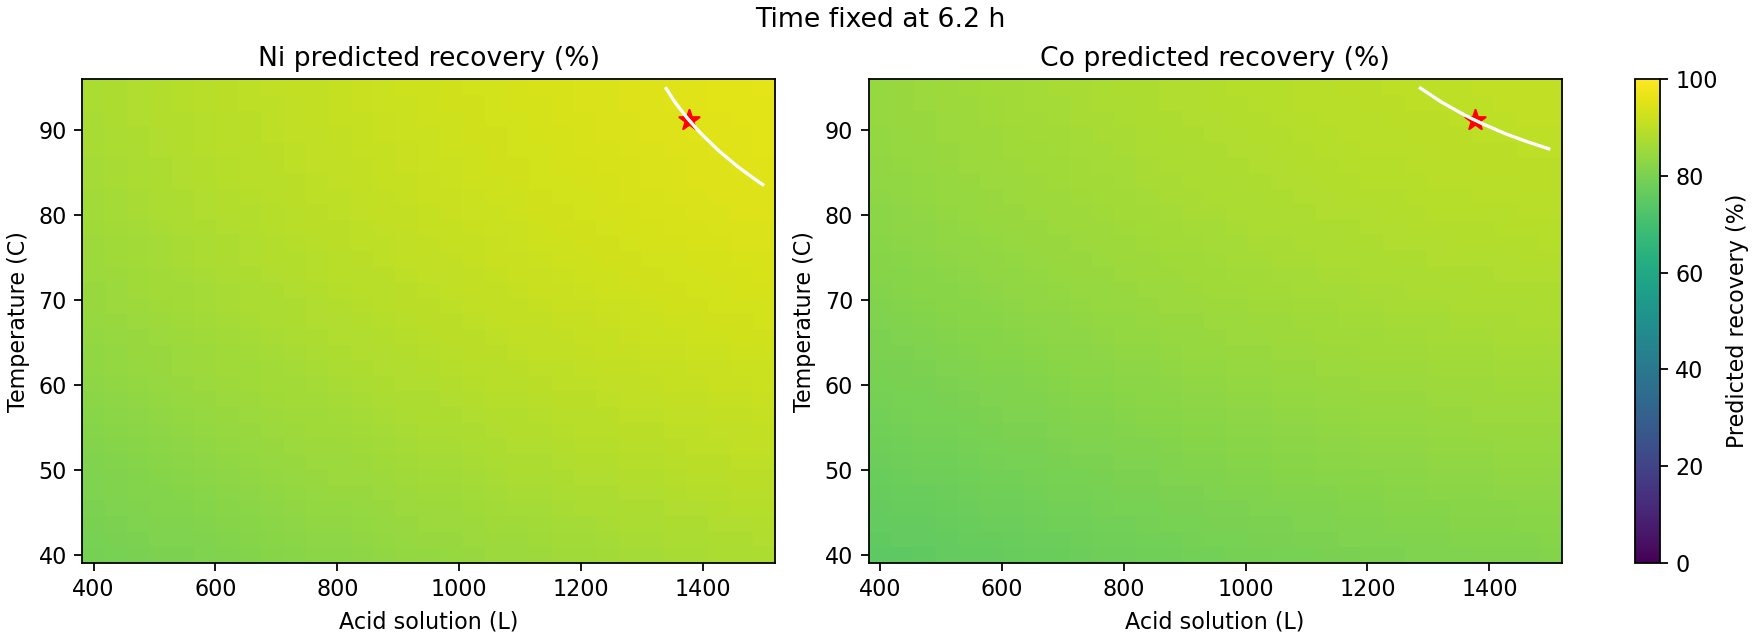

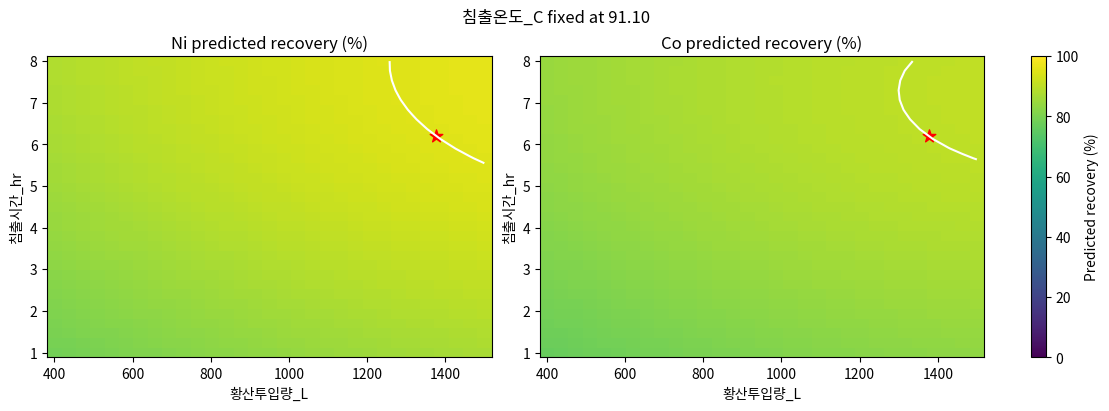

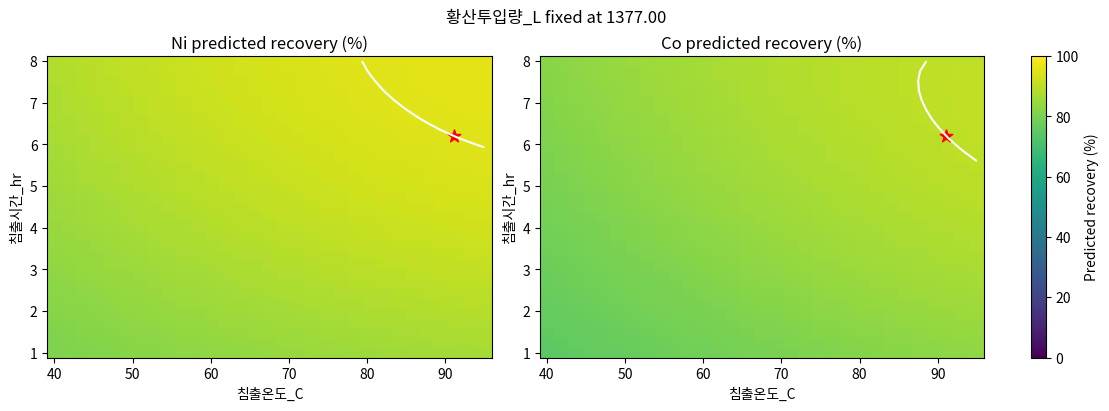

BP-2025-0066 (상태: target_not_found) — 예측 회수율 변화


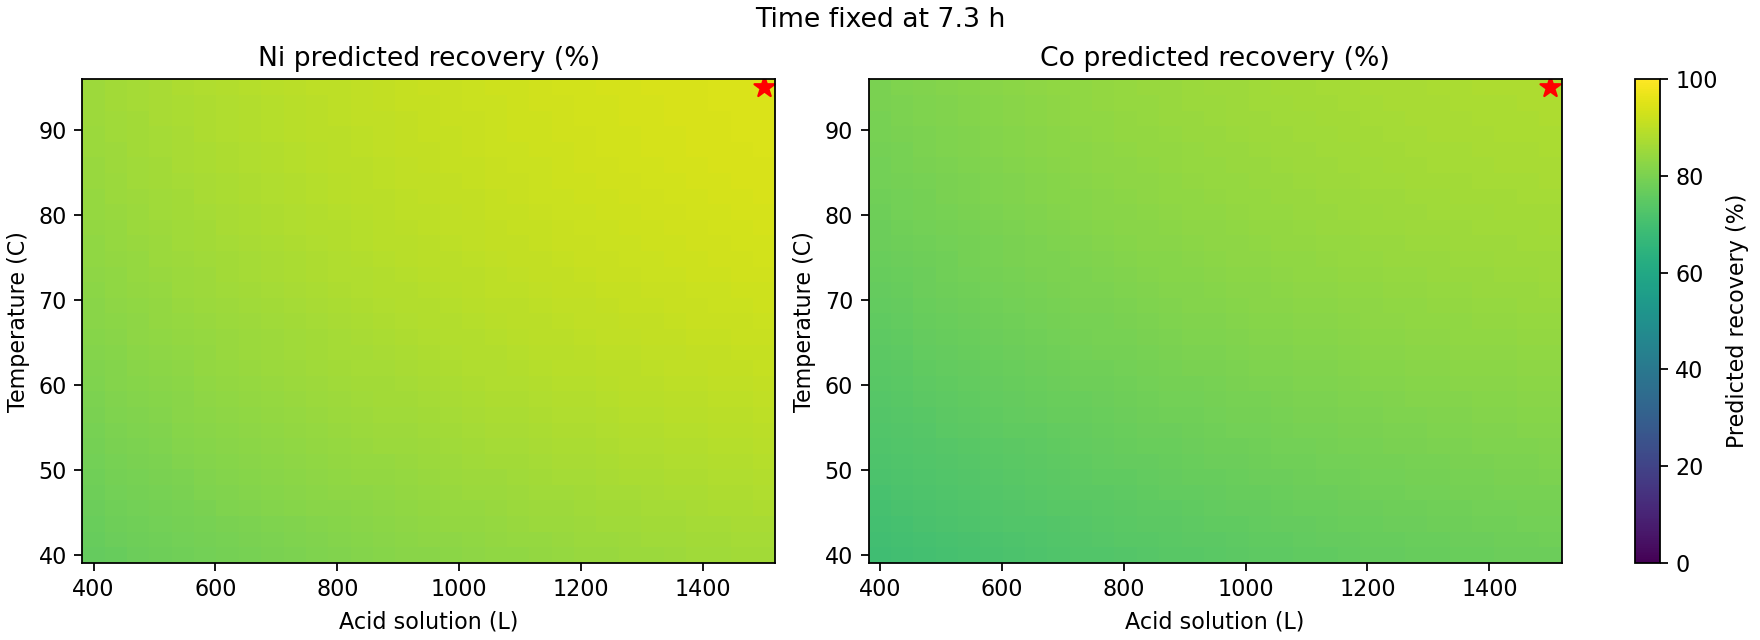

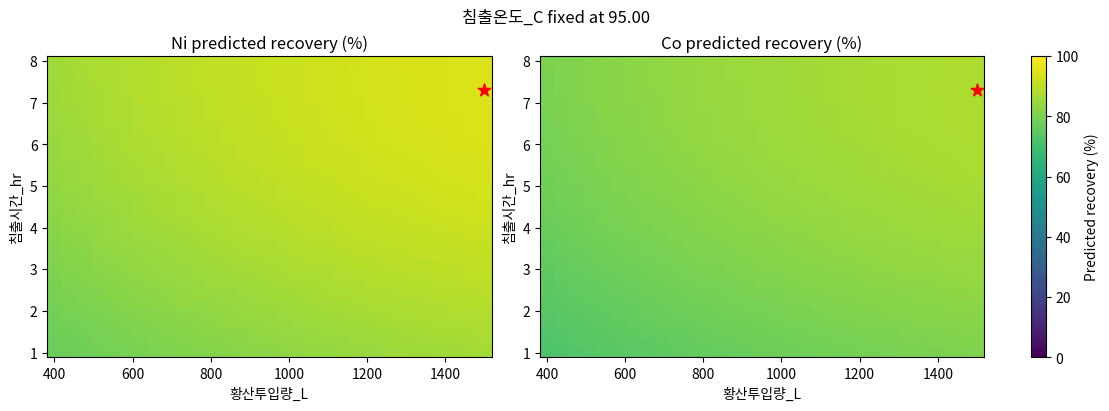

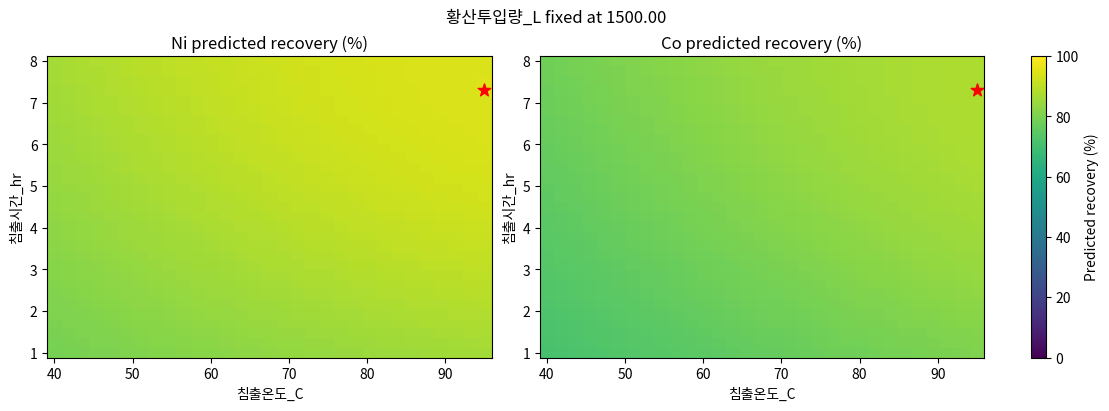

In [7]:
for batch_id, result in detail_results.items():
    print(f"{batch_id} (상태: {result['status']}) — 예측 회수율 변화")
    display(Image(filename=str(test_batch_dir / batch_id / 'recovery_surface.png')))
    plot_slice(result['feed'], result, 0, 2, 1)  # 황산-시간, 온도 고정
    plot_slice(result['feed'], result, 1, 2, 0)  # 온도-시간, 황산 고정


## 4. DE·GA seed별 결과와 격자 기준선 (가상 예제)

- §1의 가상 예제(A·C·7:3)를 대상으로 함 — Test 배치 결과가 아니므로 보고서의 Test 배치 비교 자료로 사용하지 않음(Test 배치 상세 분석은 §3)
- 알고리즘 종료 여부와 추천 목표 충족 여부를 구분함
- 전체 후보 중 유효한 반올림 후보를 비교함

In [8]:
for name, result in results.items():
    print(name)
    display(pd.read_csv(reports / name / 'search_comparison.csv'))
    display(pd.DataFrame(result['runs']))
    print('목표 대비 여유 (%p):', result['margins_pct_point'])
    print('학습 변수 범위 밖:', result['outside_training_feature_ranges'])


a_example


,source,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct,burden,deficit,valid,feasible
0,de_42,1178.0,94.4,5.3,95.364488,90.001519,0.770216,0.0,True,True
1,de_7,1172.0,94.7,5.3,95.342976,90.000263,0.770216,0.0,True,True
2,de_83,1178.0,94.4,5.3,95.364488,90.001519,0.770216,0.0,True,True
3,ga_83,1194.0,93.6,5.3,95.418956,90.001895,0.770216,0.0,True,True
4,ga_42,1206.0,93.8,5.2,95.409052,90.000636,0.770303,0.0,True,True
5,ga_7,1189.0,93.1,5.4,95.450290,90.003276,0.770433,0.0,True,True
6,grid,1225.0,88.1,6.2,95.976350,90.155874,0.789134,0.0,True,True


,algorithm,seed,converged,message,iterations,evaluations,population_size,best_score_history
0,de,7,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
1,de,42,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
2,de,83,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
3,ga,7,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[0.8979797600718197, 0.8202505649977243, 0.795..."
4,ga,42,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[0.856728496355957, 0.7820989283962227, 0.7820..."
5,ga,83,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[1.3308448840917073, 1.3308448840917073, 0.803..."


목표 대비 여유 (%p): {'Ni_회수율_pct': 0.36448819063792826, 'Co_회수율_pct': 0.001519167955009948}
학습 변수 범위 밖: {'Ni_회수율_pct': [], 'Co_회수율_pct': []}
c_example


,source,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct,burden,deficit,valid,feasible
0,de_42,1500.0,95.0,7.6,88.113341,79.224393,0.980952,17.662266,True,False
1,de_7,1500.0,95.0,7.6,88.113341,79.224393,0.980952,17.662266,True,False
2,de_83,1500.0,95.0,7.6,88.113341,79.224393,0.980952,17.662266,True,False
3,ga_42,1500.0,95.0,7.6,88.113341,79.224393,0.980952,17.662266,True,False
4,ga_7,1500.0,95.0,7.6,88.113341,79.224393,0.980952,17.662266,True,False
5,ga_83,1500.0,95.0,7.6,88.113341,79.224393,0.980952,17.662266,True,False
6,grid,1500.0,95.0,8.0,88.053165,79.227307,1.000000,17.719529,True,False


,algorithm,seed,converged,message,iterations,evaluations,population_size,best_score_history
0,de,7,True,Optimization terminated successfully.,58,2124,NaN,NaN
1,de,42,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
2,de,83,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
3,ga,7,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[20.16848355596693, 20.16848355596693, 20.1684..."
4,ga,42,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[20.760628892332385, 20.760628892332385, 20.31..."
5,ga,83,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[23.11613720479163, 23.11613720479163, 21.9314..."


목표 대비 여유 (%p): {'Ni_회수율_pct': -6.886659057836695, 'Co_회수율_pct': -10.775606684204206}
학습 변수 범위 밖: {'Ni_회수율_pct': ['침출온도_C', '황산투입량_L', 'leach_intensity'], 'Co_회수율_pct': ['침출온도_C', '황산투입량_L', 'leach_intensity']}
blend_7_3


,source,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct,burden,deficit,valid,feasible
0,de_42,1500.0,95.0,7.1,95.797849,88.996762,0.957143,1.003238,True,False
1,de_7,1500.0,95.0,7.1,95.797849,88.996762,0.957143,1.003238,True,False
2,de_83,1500.0,95.0,7.1,95.797849,88.996762,0.957143,1.003238,True,False
3,ga_42,1500.0,95.0,7.1,95.797849,88.996762,0.957143,1.003238,True,False
4,ga_7,1500.0,95.0,7.1,95.797849,88.996762,0.957143,1.003238,True,False
5,ga_83,1500.0,95.0,7.1,95.797849,88.996762,0.957143,1.003238,True,False
6,grid,1500.0,95.0,7.1,95.797849,88.996762,0.957143,1.003238,True,False


,algorithm,seed,converged,message,iterations,evaluations,population_size,best_score_history
0,de,7,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
1,de,42,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
2,de,83,False,Maximum number of iterations has been exceeded.,60,2196,NaN,NaN
3,ga,7,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[2.721510483851489, 2.721510483851489, 2.72151..."
4,ga,42,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[3.10126244369396, 3.10126244369396, 2.7156728..."
5,ga,83,None,설정한 세대 수 완료 — 수렴 판정은 별도로 수행하지 않음,60,2196,36.0,"[6.371592902395921, 6.364371138074189, 3.65932..."


목표 대비 여유 (%p): {'Ni_회수율_pct': 0.7978488747344841, 'Co_회수율_pct': -1.0032384550018207}
학습 변수 범위 밖: {'Ni_회수율_pct': ['침출온도_C', '황산투입량_L'], 'Co_회수율_pct': ['침출온도_C', '황산투입량_L']}


## 5. 조건별 예측 회수율 (가상 예제)

- §1의 가상 예제(A·C·7:3) 기준 단면임 — Test 배치 결과가 아니므로 보고서의 Test 배치 그림 자료로 사용하지 않음(Test 배치 상세 분석은 §3)
- 세 변수 중 둘을 바꾸고 나머지 하나는 추천값에 고정한 단면 3종(황산-온도·황산-시간·온도-시간)임
- 황산-온도 단면은 저장된 그림을, 나머지 둘은 노트북에서 즉시 계산함
- 흰색 선은 목표 회수율이며 범위 안에 없으면 표시하지 않음
- 별 표시는 추천 후보이며 미발견 사례에서는 목표에 가장 가까운 후보임

a_example


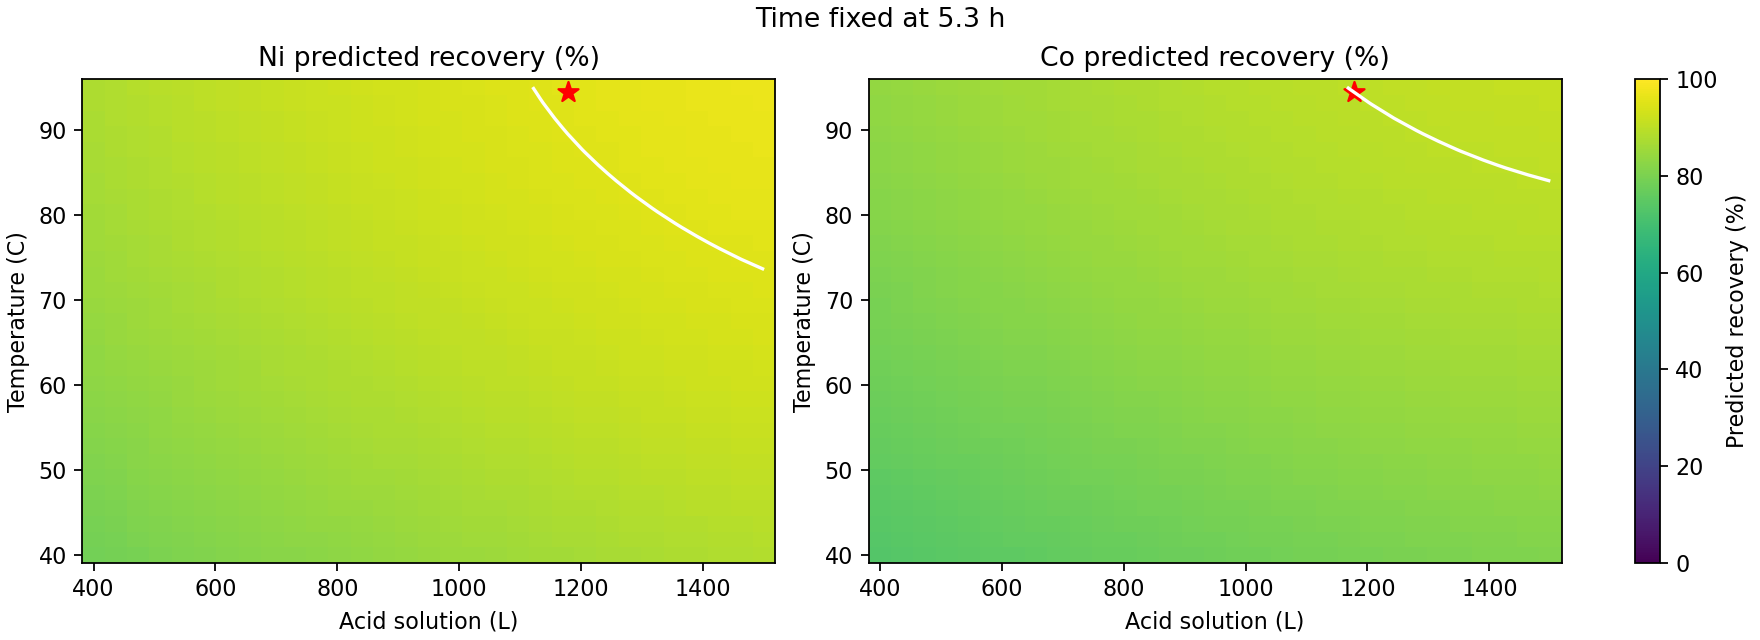

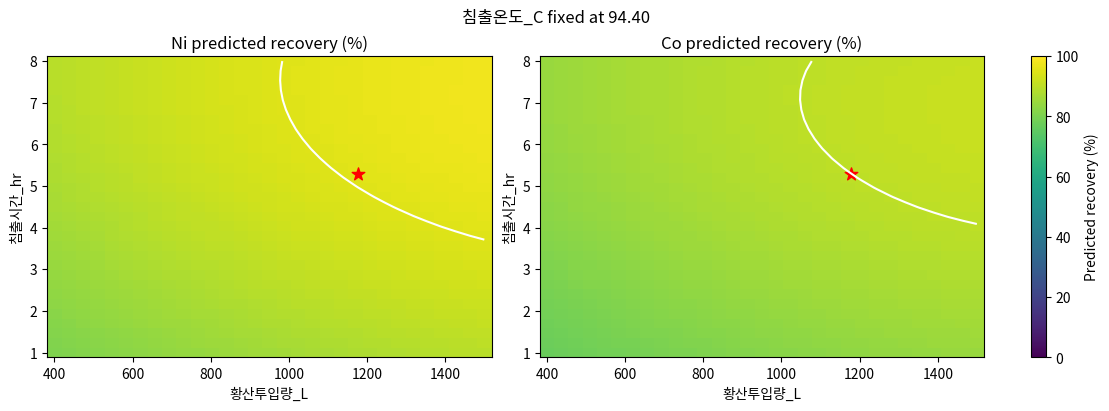

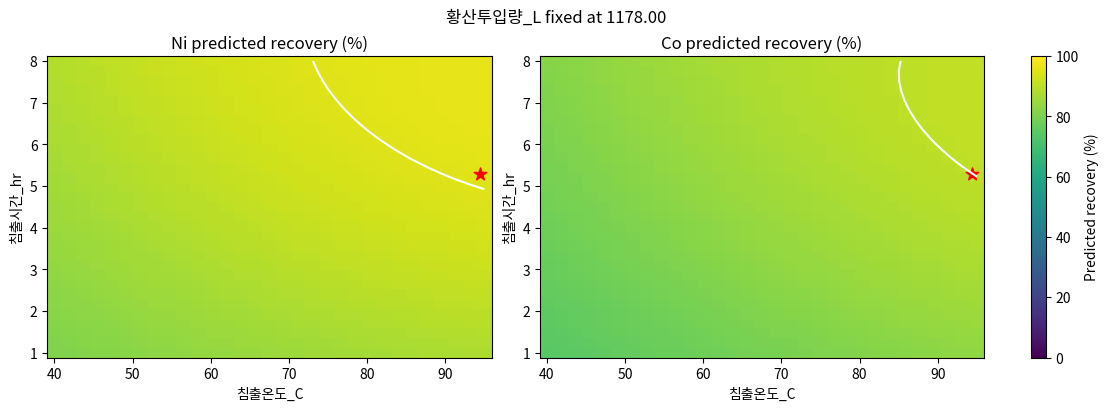

c_example


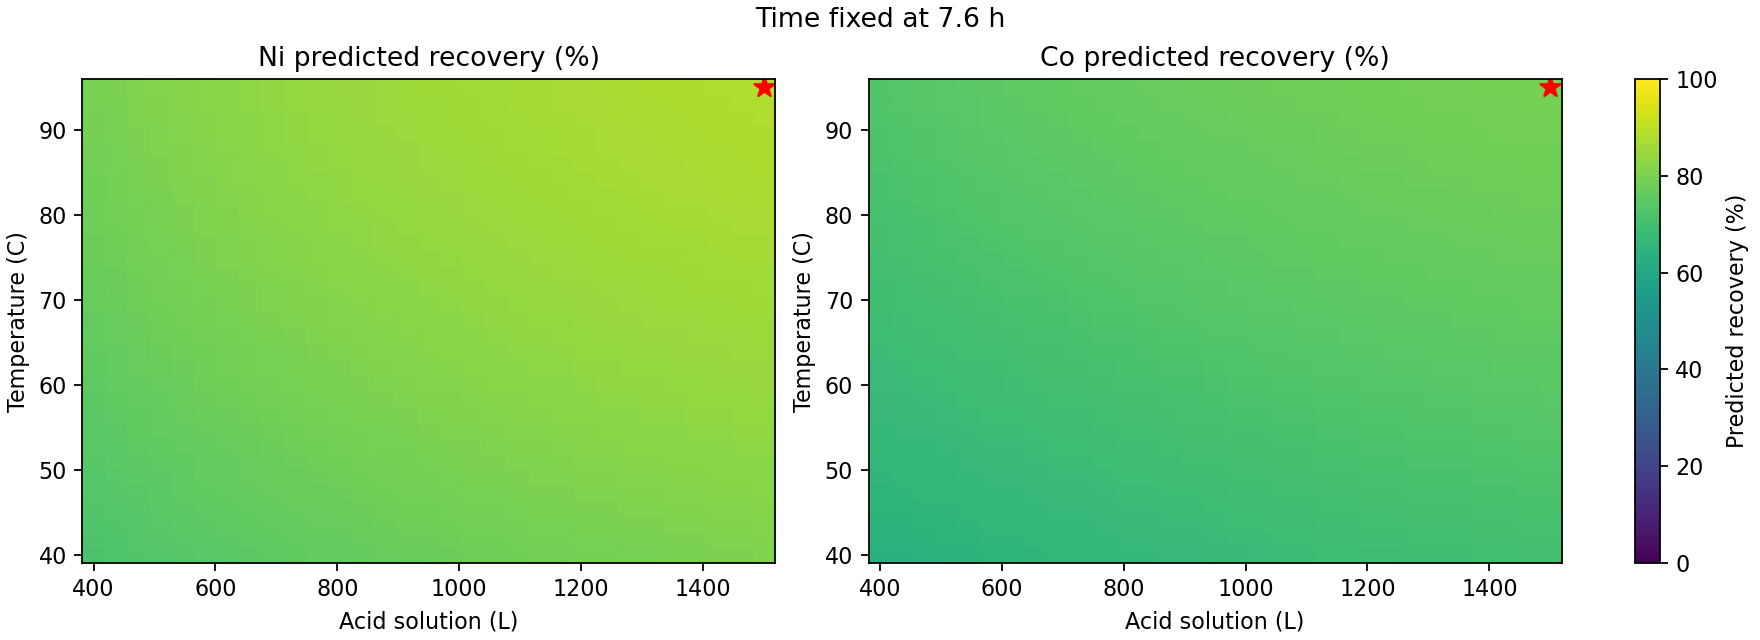

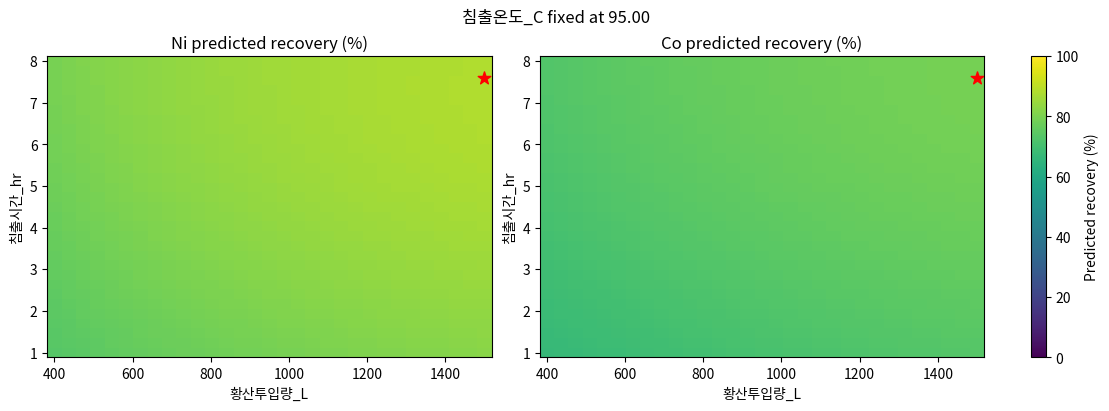

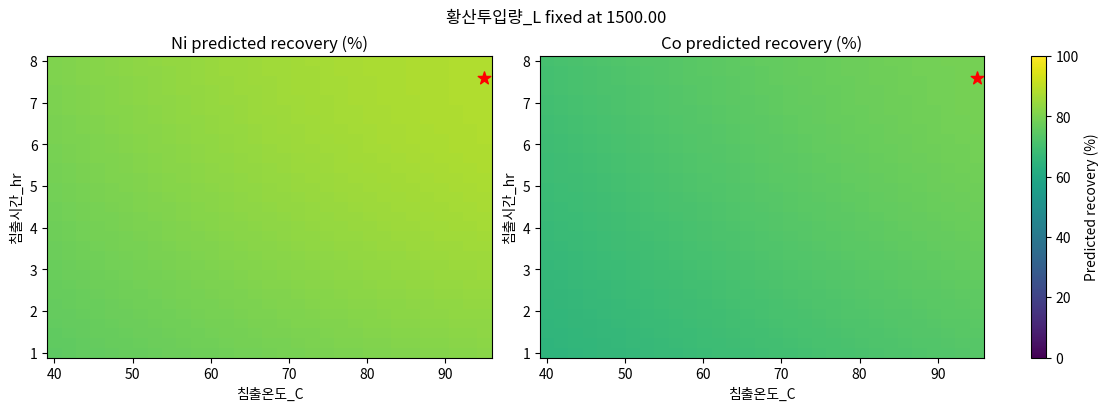

blend_7_3


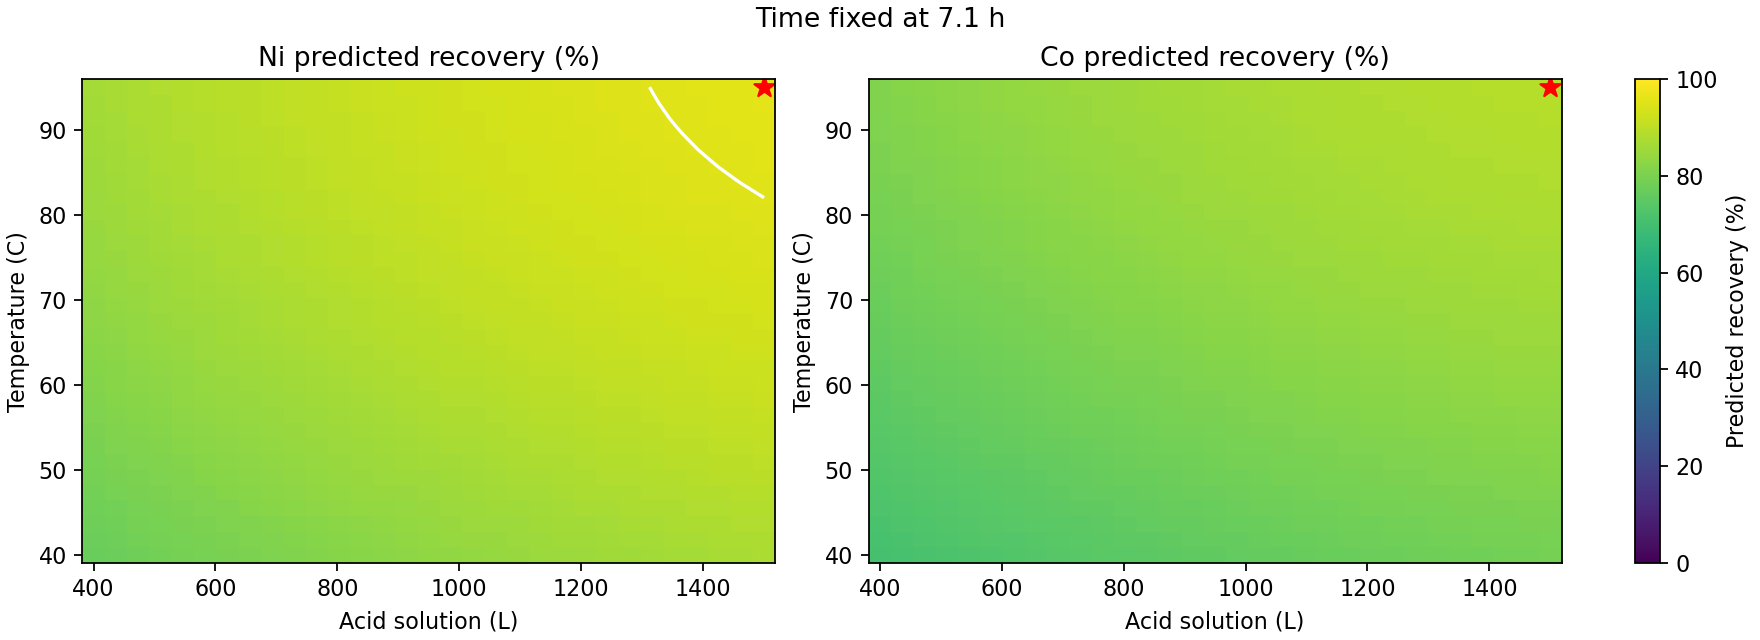

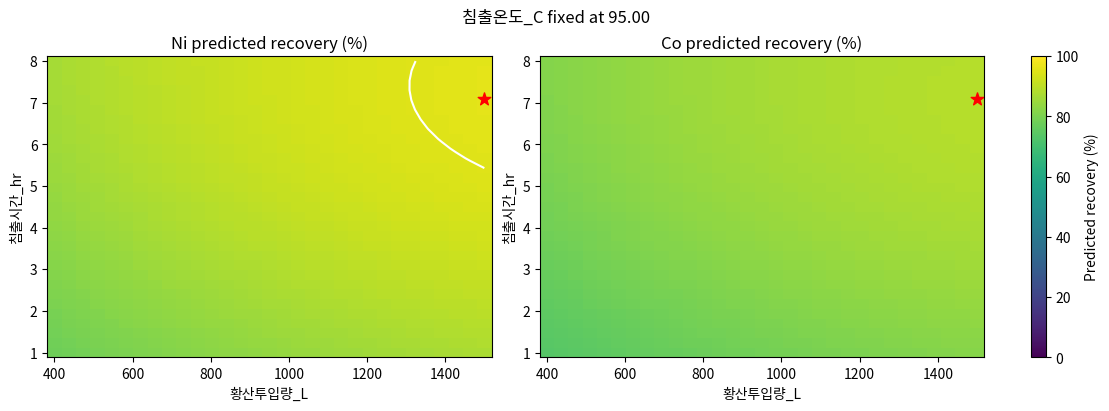

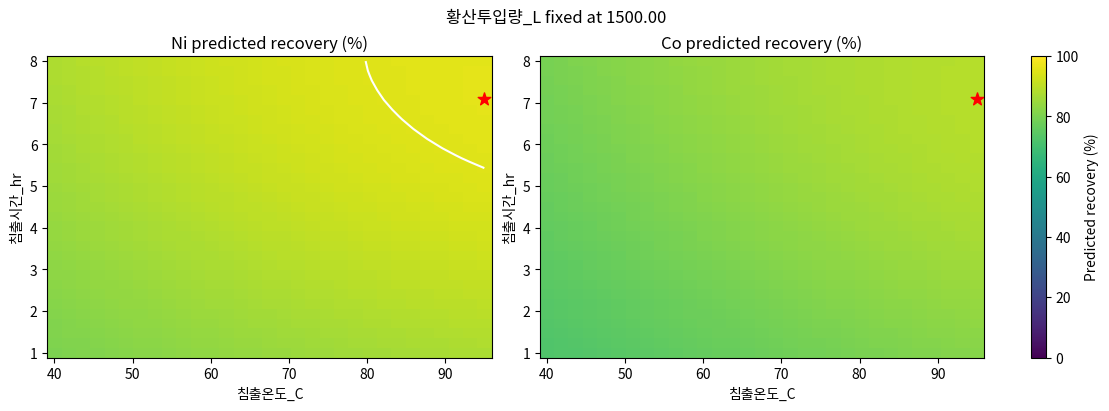

In [9]:
for name, result in results.items():
    print(name)
    display(Image(filename=str(reports / name / 'recovery_surface.png')))
    plot_slice(result['feed'], result, 0, 2, 1)  # 황산-시간, 온도 고정
    plot_slice(result['feed'], result, 1, 2, 0)  # 온도-시간, 황산 고정


## 6. 등급별 대표 조성과 혼합 비교

- 대치 전 개발 데이터 357행에서 등급별 관측 성분 중앙값 산출함
- 대표 조성은 실측 단일 배치가 아니며 Test는 산출에 사용하지 않음
- 원료 140 kg 고정 후 단독 3종·질량비 3:7, 5:5, 7:3 혼합 9종 비교함
- 각 시나리오의 운전조건을 따로 최적화하므로 동일 운전조건에서의 조성 효과 비교는 아님
- 목표 미발견은 해당 탐색 결과이며 실제 달성 불가능을 뜻하지 않음

,grade,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg
0,A,24.24,10.91,4.58,8.99,0.740,0.600,1.20,140.0
1,B,18.16,7.68,3.80,10.83,1.765,1.510,2.60,140.0
2,C,12.08,5.00,2.93,12.03,3.510,3.145,4.47,140.0


,scenario,status,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct,Ni_margin,Co_margin,burden,selected_source,outside_training_ranges
0,A,predicted_feasible,1165.0,92.0,5.2,95.479748,90.001467,0.479748,0.001467,0.746970,de_42,False
1,B,target_not_found,1500.0,95.0,7.1,95.777427,89.244453,0.777427,-0.755547,0.957143,de_42,True
2,C,target_not_found,1500.0,95.0,7.4,90.339927,81.712744,-4.660073,-8.287256,0.971429,de_42,True
3,AB_3_7,predicted_feasible,1445.0,95.0,5.9,96.156711,90.001962,1.156711,0.001962,0.883333,de_42,True
4,AB_5_5,predicted_feasible,1320.0,95.0,5.5,95.850294,90.001060,0.850294,0.001060,0.826407,de_7,True
5,AB_7_3,predicted_feasible,1239.0,95.0,5.2,95.597897,90.000170,0.597897,0.000170,0.787576,de_42,True
6,AC_3_7,target_not_found,1500.0,95.0,7.3,93.219960,85.606149,-1.780040,-4.393851,0.966667,de_42,True
7,AC_5_5,target_not_found,1500.0,95.0,7.2,95.032750,88.014679,0.032750,-1.985321,0.961905,de_42,True
8,AC_7_3,predicted_feasible,1496.0,95.0,6.5,96.481624,90.000932,1.481624,0.000932,0.927359,de_42,True
9,BC_3_7,target_not_found,1500.0,95.0,7.3,92.045414,84.063250,-2.954586,-5.936750,0.966667,de_42,True


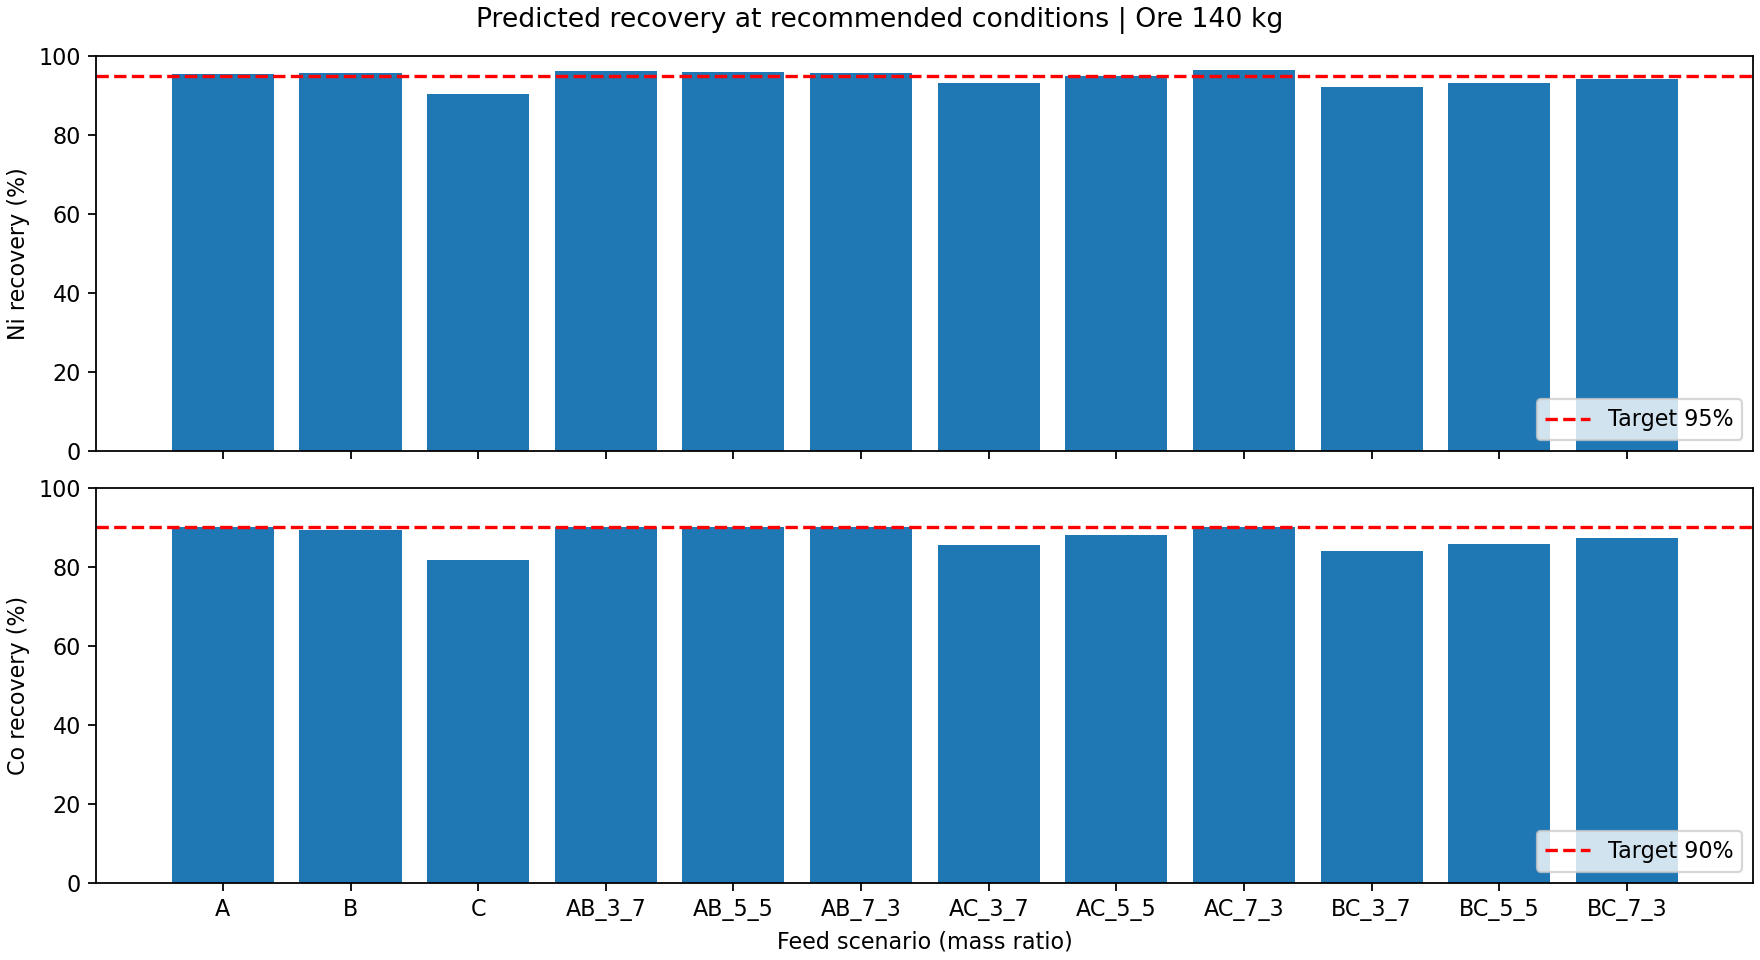

In [10]:
comparison_dir = reports / 'representative_blends'
display(pd.read_csv(comparison_dir / 'representative_compositions.csv'))
display(pd.read_csv(comparison_dir / 'summary.csv'))
display(Image(filename=str(comparison_dir / 'blend_comparison.png')))

## 7. B급 원료 투입량 비교

- 기존 목적함수와 별도로 Ni 95% 이상 제약 아래 Co 예측 회수율 최대화함
- 140 kg은 기존 데이터사전 범위로 먼저 비교함
- 원료량별 비교는 학습 관측 범위 안의 81·100·120·140·160·180·199 kg 7개 지점을 사용함
- 운전조건 및 파생변수를 포함한 모델 입력별 학습 최솟값·최댓값 안으로 제한함
- 각 투입량에서 공정조건을 별도로 탐색하고 반올림 후 재예측함
- 변수별 범위 준수가 조합 전체의 학습 지원이나 실제 달성을 보장하지 않음
- 처리량 감소와 배치당 예상 회수 금속량을 함께 비교하며 실제 비용·시간당 생산성은 평가하지 않음

,scenario,ore_kg,training_ranges_enforced,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct,status,ore_change_pct,predicted_Ni_kg,predicted_Co_kg
0,dictionary_140,140,False,1500.0,95.0,7.1,95.777427,89.244453,target_not_found,0.000000,24.350453,9.595564
1,training_81,81,True,1340.0,94.9,6.8,96.828655,90.417013,predicted_feasible,-42.142857,14.243108,5.624662
2,training_100,100,True,1495.0,94.9,6.9,96.917800,90.428872,predicted_feasible,-28.571429,17.600272,6.944937
3,training_120,120,True,1495.0,94.9,7.0,96.458847,89.974807,target_not_found,-14.285714,21.020312,8.292078
4,training_140,140,True,1495.0,94.9,7.1,95.759285,89.225810,target_not_found,0.000000,24.345841,9.593559
5,training_160,160,True,1495.0,94.9,7.3,94.951288,88.324107,target_not_found,14.285714,27.589046,10.853266
6,training_180,180,True,1495.0,94.9,7.3,94.078530,87.341277,target_not_found,28.571429,30.752390,12.074058
7,training_199,199,True,1495.0,94.9,7.3,93.207962,86.351745,target_not_found,42.142857,33.683866,13.197310


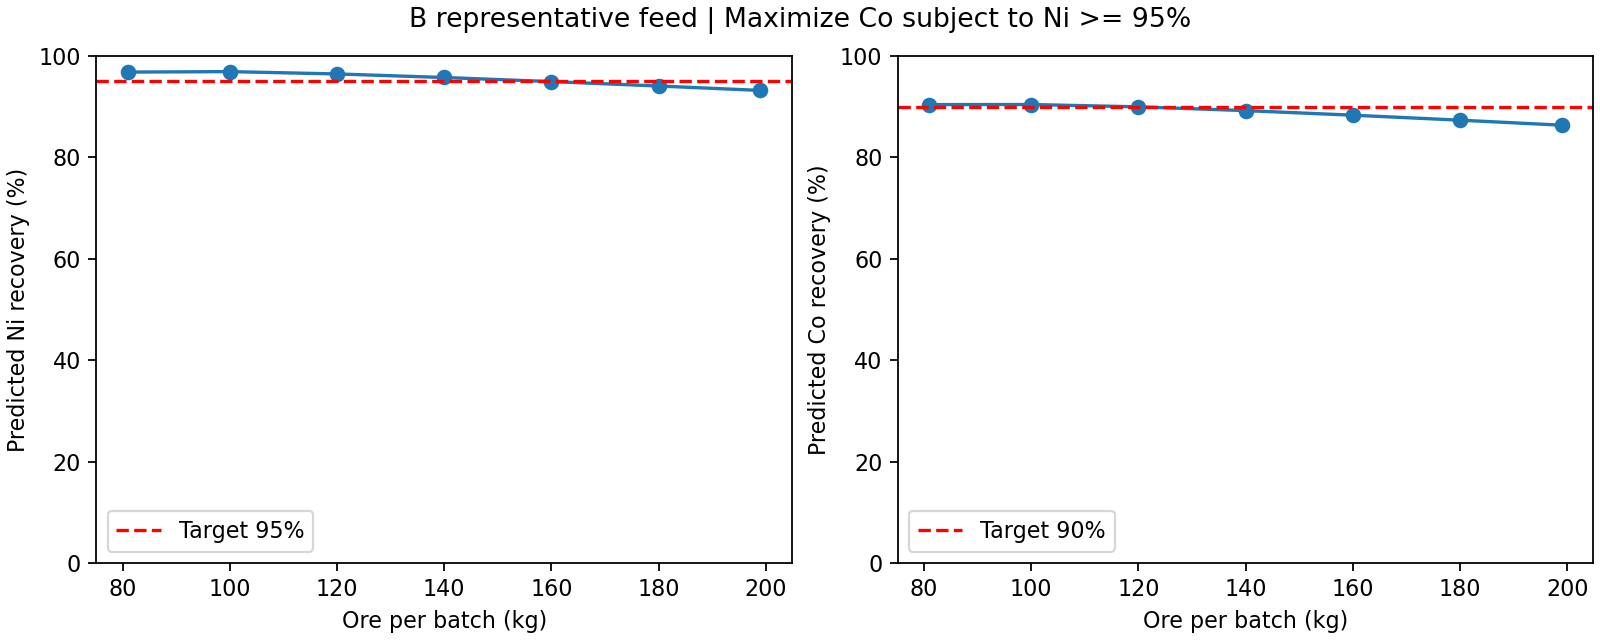

In [11]:
capacity_dir = reports / 'b_grade_capacity'
display(pd.read_csv(capacity_dir / 'summary.csv'))
display(Image(filename=str(capacity_dir / 'ore_sensitivity.png')))

## 8. 한계

- 실험실·현장 검증 전이므로 실제 회수율·경제적 효과를 보장하지 않음
- 학습 변수별 범위 검사는 조합 전체의 학습 분포 포함 여부를 보장하지 않음
- 모델 예측을 0~100으로 잘라 목표 충족시키지 않으며 범위 밖 예측은 제외함
- CV·Test 오차를 신뢰구간으로 간주하지 않음
- 모델 재학습·Test 재선택은 수행하지 않음


## 9. 기대효과 및 활용 방안

**기대효과**
- 원료 성분 분석값과 예정 공정조건을 바탕으로 Ni·Co 회수율을 사전에 예측해, 원료 투입 전에 저회수율이 예상되는 배치를 미리 파악할 수 있음
- 목표 회수율에 못 미칠 것으로 예측되는 원료에 대해, 운전조건(황산량·온도·시간) 조정으로 개선 여지가 있는지 실험 전에 먼저 탐색할 수 있음(§2 Test 배치 비교에서 추천 조건이 기존 조건보다 예측상 회수율이 높게 나온 경우가 다수였음 — 예측상 개선이며 실측 재현은 별도 확인 필요)

**활용 방안 (제안 순서)**
1. **현장 실증**: 추천 조건 중 일부를 소규모로 실제 공정에 시험 적용해, 모델 예측과 실측 회수율의 차이를 확인함
2. **원료별 예측 오차 확인**: §6(Module 2 노트북)의 등급별 오차 분석과 같은 방식을 운영 데이터에도 주기적으로 적용해, 특정 등급·원료 구간에서 예측 오차가 커지는지 모니터링함
3. **추천 조건 시험**: Ni 95%·Co 90% 외에도 설비 한계·비용 등 현장 제약에 맞춰 목표·가중치를 바꿔 재추천을 받고, 그 결과를 소규모로 시험함
4. **공정 기록 활용**: 실증으로 쌓인 실제 운전조건·회수율 기록으로 Module 1~2를 주기적으로 재실행해, 모델이 최신 공정 데이터를 반영하도록 갱신함

**전제와 한계**
- 이 제안은 현재 모델·탐색 범위의 예측에 근거하며, §8의 한계와 동일하게 실험실·현장 검증 전 단계임
- 실제 도입 전 공정 안전성·설비 제약 검토가 선행되어야 함
